# Step 0: check the new sequences

Same pipeline as `01_loader.ipynb`, run on another sequence. Change `SEQ` and `TAG` in the first cell, then run all cells.

Pass: the green box is on a vehicle, and a red CFAR dot is within about 5 range bins of the dashed label line.

In [41]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

SEQ  = "RECORD@2020-11-21_13.46.26"   # city.  highway: "RECORD@2020-11-22_12.38.47"   countryside: "RECORD@2020-11-22_12.54.38"
TAG  = "city"                         # "highway" / "countryside"; goes into the saved figure name
DATA = rf"C:\Users\daksh\Documents\SPARSE_FFT\data\{SEQ}\{SEQ}"

log_path = os.path.join(DATA, SEQ + "_events_log.rec")
print(os.path.exists(log_path))       # must print True

True


In [42]:
radar = {"radar_ch0": {}, "radar_ch1": {}, "radar_ch2": {}, "radar_ch3": {}}

with open(log_path) as f:
    for line in f:
        pieces = line.split()
        if len(pieces) != 17:
            continue
        sensor = pieces[10]
        if sensor not in radar:
            continue
        sample   = int(pieces[7])
        offset   = int(pieces[13])
        datasize = int(pieces[16])
        radar[sensor][sample] = (offset, datasize)

for name in radar:
    print(name, len(radar[name]))     # city: about 586-591 each, highway: about 488-493

radar_ch0 586
radar_ch1 589
radar_ch2 589
radar_ch3 591


In [43]:
frames = []                           # ch3 sample numbers that have all 4 chips

for n in radar["radar_ch3"]:
    if (n + 1) in radar["radar_ch0"] and (n + 2) in radar["radar_ch2"] and (n + 3) in radar["radar_ch1"]:
        frames.append(n)

print(len(frames), frames[0], frames[-1])   # city: 576 frames, highway: 483

576 14833 17186


In [44]:
def read_block(chip, offset, datasize):
    path = os.path.join(DATA, SEQ + f"_{chip}.bin")
    with open(path, "rb") as f:
        f.seek(offset)
        x = np.fromfile(f, dtype=np.int16, count=datasize//2)
    return x

def chip_cube(x):
    c = x[0::2] + 1j * x[1::2]
    c = np.reshape(c, (512, 4, 256), order="F")
    return c.transpose((0, 2, 1))

In [45]:
# Hamming windows (frame_to_pred needs these)
N, M = 512, 256
w_range   = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(N) / (N - 1))
w_doppler = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(M) / (M - 1))

In [46]:
from scipy.signal import convolve2d

def ca_cfar(P, n_rng=9, n_dop=9, g_rng=3, g_dop=3, thr_db=4):
    pw = np.abs(P) ** 2
    mask = np.ones((2*n_rng + 1, 2*n_dop + 1))
    mask[n_rng-g_rng : n_rng+g_rng+1, n_dop-g_dop : n_dop+g_dop+1] = 0

    sums   = convolve2d(pw, mask, mode="same")
    counts = convolve2d(np.ones_like(pw), mask, mode="same")
    noise  = sums / counts
    snr    = pw / noise
    return snr > 10 ** (thr_db / 10)

In [47]:
def frame_to_pred(n, mti=False):
    keys = [("radar_ch3", n), ("radar_ch0", n+1), ("radar_ch1", n+3), ("radar_ch2", n+2)]

    cubes = []
    for chip, s in keys:
        off, size = radar[chip][s]
        cubes.append(chip_cube(read_block(chip, off, size)))   # each is (512, 256, 4)

    cube = np.concatenate(cubes, axis=2)                     # -> (512, 256, 16)
    if mti:
        cube = cube - cube.mean(axis=1, keepdims=True)
    else:
        cube = cube - cube.mean(axis=(0, 1), keepdims=True)

    rng = np.fft.fft(cube * w_range[:, None, None],   axis=0)
    rd  = np.fft.fft(rng  * w_doppler[None, :, None], axis=1)

    Pm = np.sum(np.abs(rd), axis=2)
    return Pm.reshape(512, 16, 16).sum(axis=1)

In [48]:
labels = pd.read_csv("../data/labels_CVPR.csv")
lab = labels[labels["dataset"] == SEQ]

M_PER_BIN = 103 / 512
lab = lab.assign(range_bin = lab["radar_R_m"] / M_PER_BIN)

ks = sorted(lab["index"].unique())
print(len(ks), len(lab), ks[:5])     # city: 292 frames, 1061 vehicles; highway: 321, 343

292 1061 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6)]


In [49]:
cam_ts, cam_tio, cam_off, cam_size = [], [], [], []
ch3_ts, ch3_tio = {}, {}

with open(log_path) as f:
    for line in f:
        p = line.split()
        if len(p) != 17: continue
        if p[10] == "camera":
            cam_ts.append(int(p[1]));    cam_tio.append(int(p[4]))
            cam_off.append(int(p[13]));  cam_size.append(int(p[16]))
        elif p[10] == "radar_ch3":
            ch3_ts[int(p[7])] = int(p[1]);  ch3_tio[int(p[7])] = int(p[4])

cam_tio = np.array(cam_tio)

def camera_for(n):
    return int(np.argmin(np.abs(cam_tio - ch3_tio[n])))     # closest picture by time of issue

cam_path = os.path.join(DATA, SEQ + "_camera.mjpg")
def read_image(j):
    with open(cam_path, "rb") as f:
        f.seek(cam_off[j])
        data = f.read(cam_size[j])
    return cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)

print(len(cam_tio), "camera pictures")

3411 camera pictures


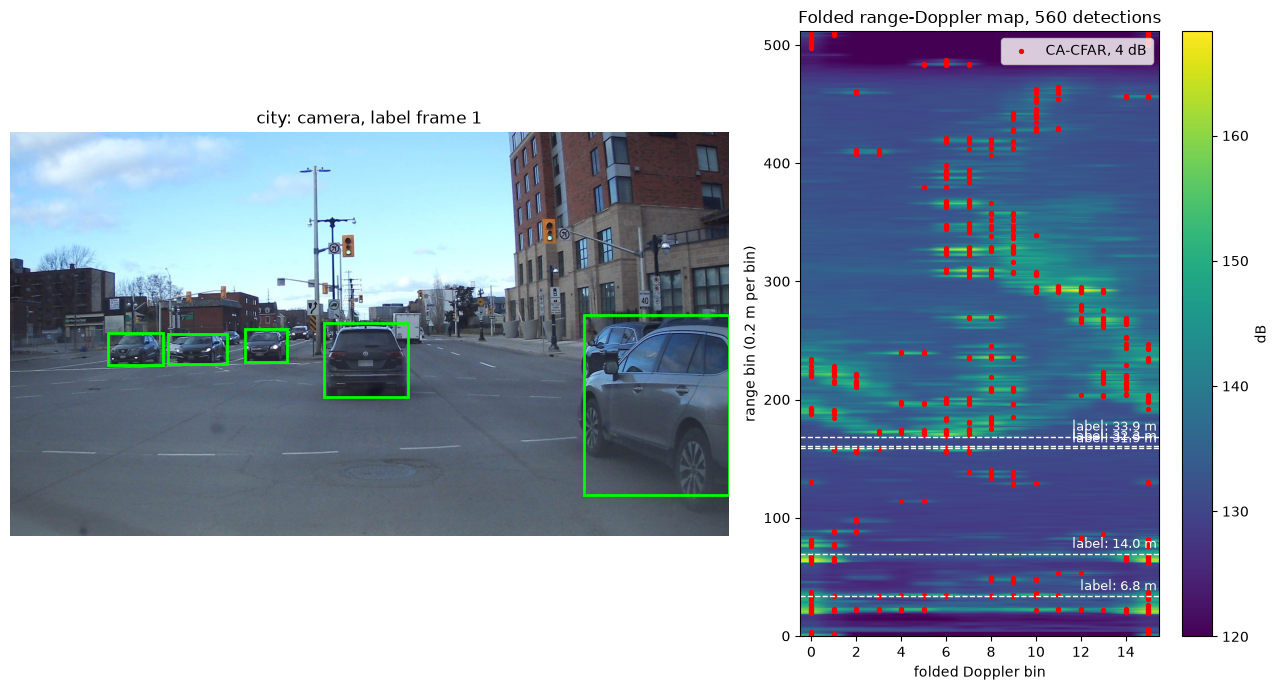

In [50]:
k = ks[0]                                  # first labelled frame; try ks[100] or ks[200] as well
P = frame_to_pred(frames[k])
hits = ca_cfar(P, thr_db=4)                # the frozen threshold
det = np.argwhere(hits)
fk = lab[lab["index"] == k]
img = read_image(camera_for(frames[k]))

fig, ax = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [1.6, 1]})

ax[0].imshow(img[:, :, ::-1]); ax[0].axis("off")
ax[0].set_title(f"{TAG}: camera, label frame {k}")
for _, r in fk.iterrows():
    ax[0].add_patch(plt.Rectangle((r["x1_pix"], r["y1_pix"]), r["x2_pix"] - r["x1_pix"], r["y2_pix"] - r["y1_pix"],
                                  fill=False, ec="lime", lw=2))

im = ax[1].imshow(20*np.log10(P + 1e-9), aspect="auto", origin="lower", vmin=120)
ax[1].scatter(det[:, 1], det[:, 0], s=8, c="r", label="CA-CFAR, 4 dB")
for rb, r in zip(fk["range_bin"], fk["radar_R_m"]):
    ax[1].axhline(rb, color="w", ls="--", lw=1)
    ax[1].text(15.4, rb + 5, f"label: {r:.1f} m", color="w", ha="right", fontsize=9)
ax[1].set_xlabel("folded Doppler bin")
ax[1].set_ylabel("range bin (0.2 m per bin)")
ax[1].set_title(f"Folded range-Doppler map, {hits.sum()} detections")
ax[1].legend(loc="upper right")
fig.colorbar(im, ax=ax[1], label="dB")

plt.tight_layout()
plt.savefig(f"../figures/fig1_{TAG}_k{k}.png", dpi=150, bbox_inches="tight")
plt.show()